# **Assignment 4. Supervised learning model: Decision tree**

*Authors:*

*   Camila García Vázquez **2177743**
*   Alan Zahir Lopez Rodriguez **2103115**
*   Ezequiel Sandoval Puerto **2061522**
*   Arleth Cassandra Andrade Cordova **1896113**



*Class schedule:* Thursday N3-N6


**1. Load libraries**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

**Explanation:**

> First, we imported the libraries needed for this activity. Pandas will help us organize the data, while scikit-learn provides the dataset and the function to divide it into training and testing sets.

**2. Load data**

In [ ]:

# Load the breast cancer dataset
dataset = load_breast_cancer()

# Separate the features and the diagnosis
data = pd.DataFrame(dataset.data, columns=dataset.feature_names)
labels = pd.Series(dataset.target, name="diagnosis")

# Check the dataset information
print("Dataset size:", data.shape)
print("Features:", len(dataset.feature_names))
print("Classes:", dataset.target_names)
print("Samples per class:")
print(labels.value_counts().sort_index())
print("Missing values:", data.isnull().sum().sum())

# Look at the first five samples
display(data.head())


Dataset size: (569, 30)
Features: 30
Classes: ['malignant' 'benign']
Samples per class:
diagnosis
0    212
1    357
Name: count, dtype: int64
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Explanation:**
> We loaded the Breast Cancer Wisconsin dataset from scikit-learn. It contains 569 samples and 30 features related to tumor characteristics. The diagnoses are divided into two classes: malignant (0) and benign (1).

> We separated the features from the diagnoses and checked the dataset to see how the information was organized. We also looked for missing values and displayed the first five rows.

**3. Data preprocessing**

In [ ]:

# Use 80% of the samples for training and 20% for testing
train_data, test_data, train_labels, test_label = train_test_split(
    data,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

# Verify the number of samples in each group
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)
print("Training labels:", train_labels.shape)
print("Testing labels:", test_label.shape)


Training data: (455, 30)
Testing data: (114, 30)
Training labels: (455,)
Testing labels: (114,)


**Explanation:**
> We divided the 569 samples into two groups: 455 for training and 114 for testing. We used random_state=42 so we get the same split when we run the notebook again. We also used stratify=labels to keep a similar proportion of malignant and benign cases in both groups. The test data is kept separate from the training process.

**4. Model selection and training**

In [ ]:
# Create a decision tree using Gini impurity and a maximum depth of four
clf = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

# Train the model with the training samples and their diagnoses
clf.fit(train_data, train_labels)

print("Decision Tree model trained successfully!")
print("Tree depth:", clf.get_depth())
print("Number of leaves:", clf.get_n_leaves())

Decision Tree model trained successfully!
Tree depth: 4
Number of leaves: 11



**Explanation:**

> We selected DecisionTreeClassifier because the goal is to predict whether a sample is malignant or benign from its measurements. We used the Gini criterion to choose the splits and set max_depth=4 to keep the tree from becoming too large. The fit() function trains it using only the training data and labels.





**5. Model testing**

**Predictions and evaluation**

In [ ]:
# Predict diagnoses for the samples that were left out of training
predictions = clf.predict(test_data)

# Compare the predictions with the real diagnoses
accuracy = accuracy_score(test_label, predictions)
print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Correct predictions: {(predictions == test_label).sum()} of {len(test_label)}\n")

# Look at precision, recall, F1-score and support for each class
report = classification_report(
    test_label,
    predictions,
    target_names=["Malignant (0)", "Benign (1)"],
    digits=4
)
print("Classification report:")
print(report)

# Rows: actual cases (malignant, benign); columns: predicted cases
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(test_label, predictions))

Test accuracy: 0.9386 (93.86%)
Correct predictions: 107 of 114

Classification report:
               precision    recall  f1-score   support

Malignant (0)     0.9070    0.9286    0.9176        42
   Benign (1)     0.9577    0.9444    0.9510        72

     accuracy                         0.9386       114
    macro avg     0.9324    0.9365    0.9343       114
 weighted avg     0.9390    0.9386    0.9387       114

Confusion matrix (rows = actual, columns = predicted):
[[39  3]
 [ 4 68]]


**Explanation**:



> The predict() function was used with the 114 testing samples. We then compared the predicted diagnoses with the real labels using accuracy_score(). The classification report gives more detail through precision, recall and F1-score for each class. We also printed a confusion matrix to see the number of correct and incorrect predictions.



**Decision tree visualization**

**Create the Decision Tree Figure**

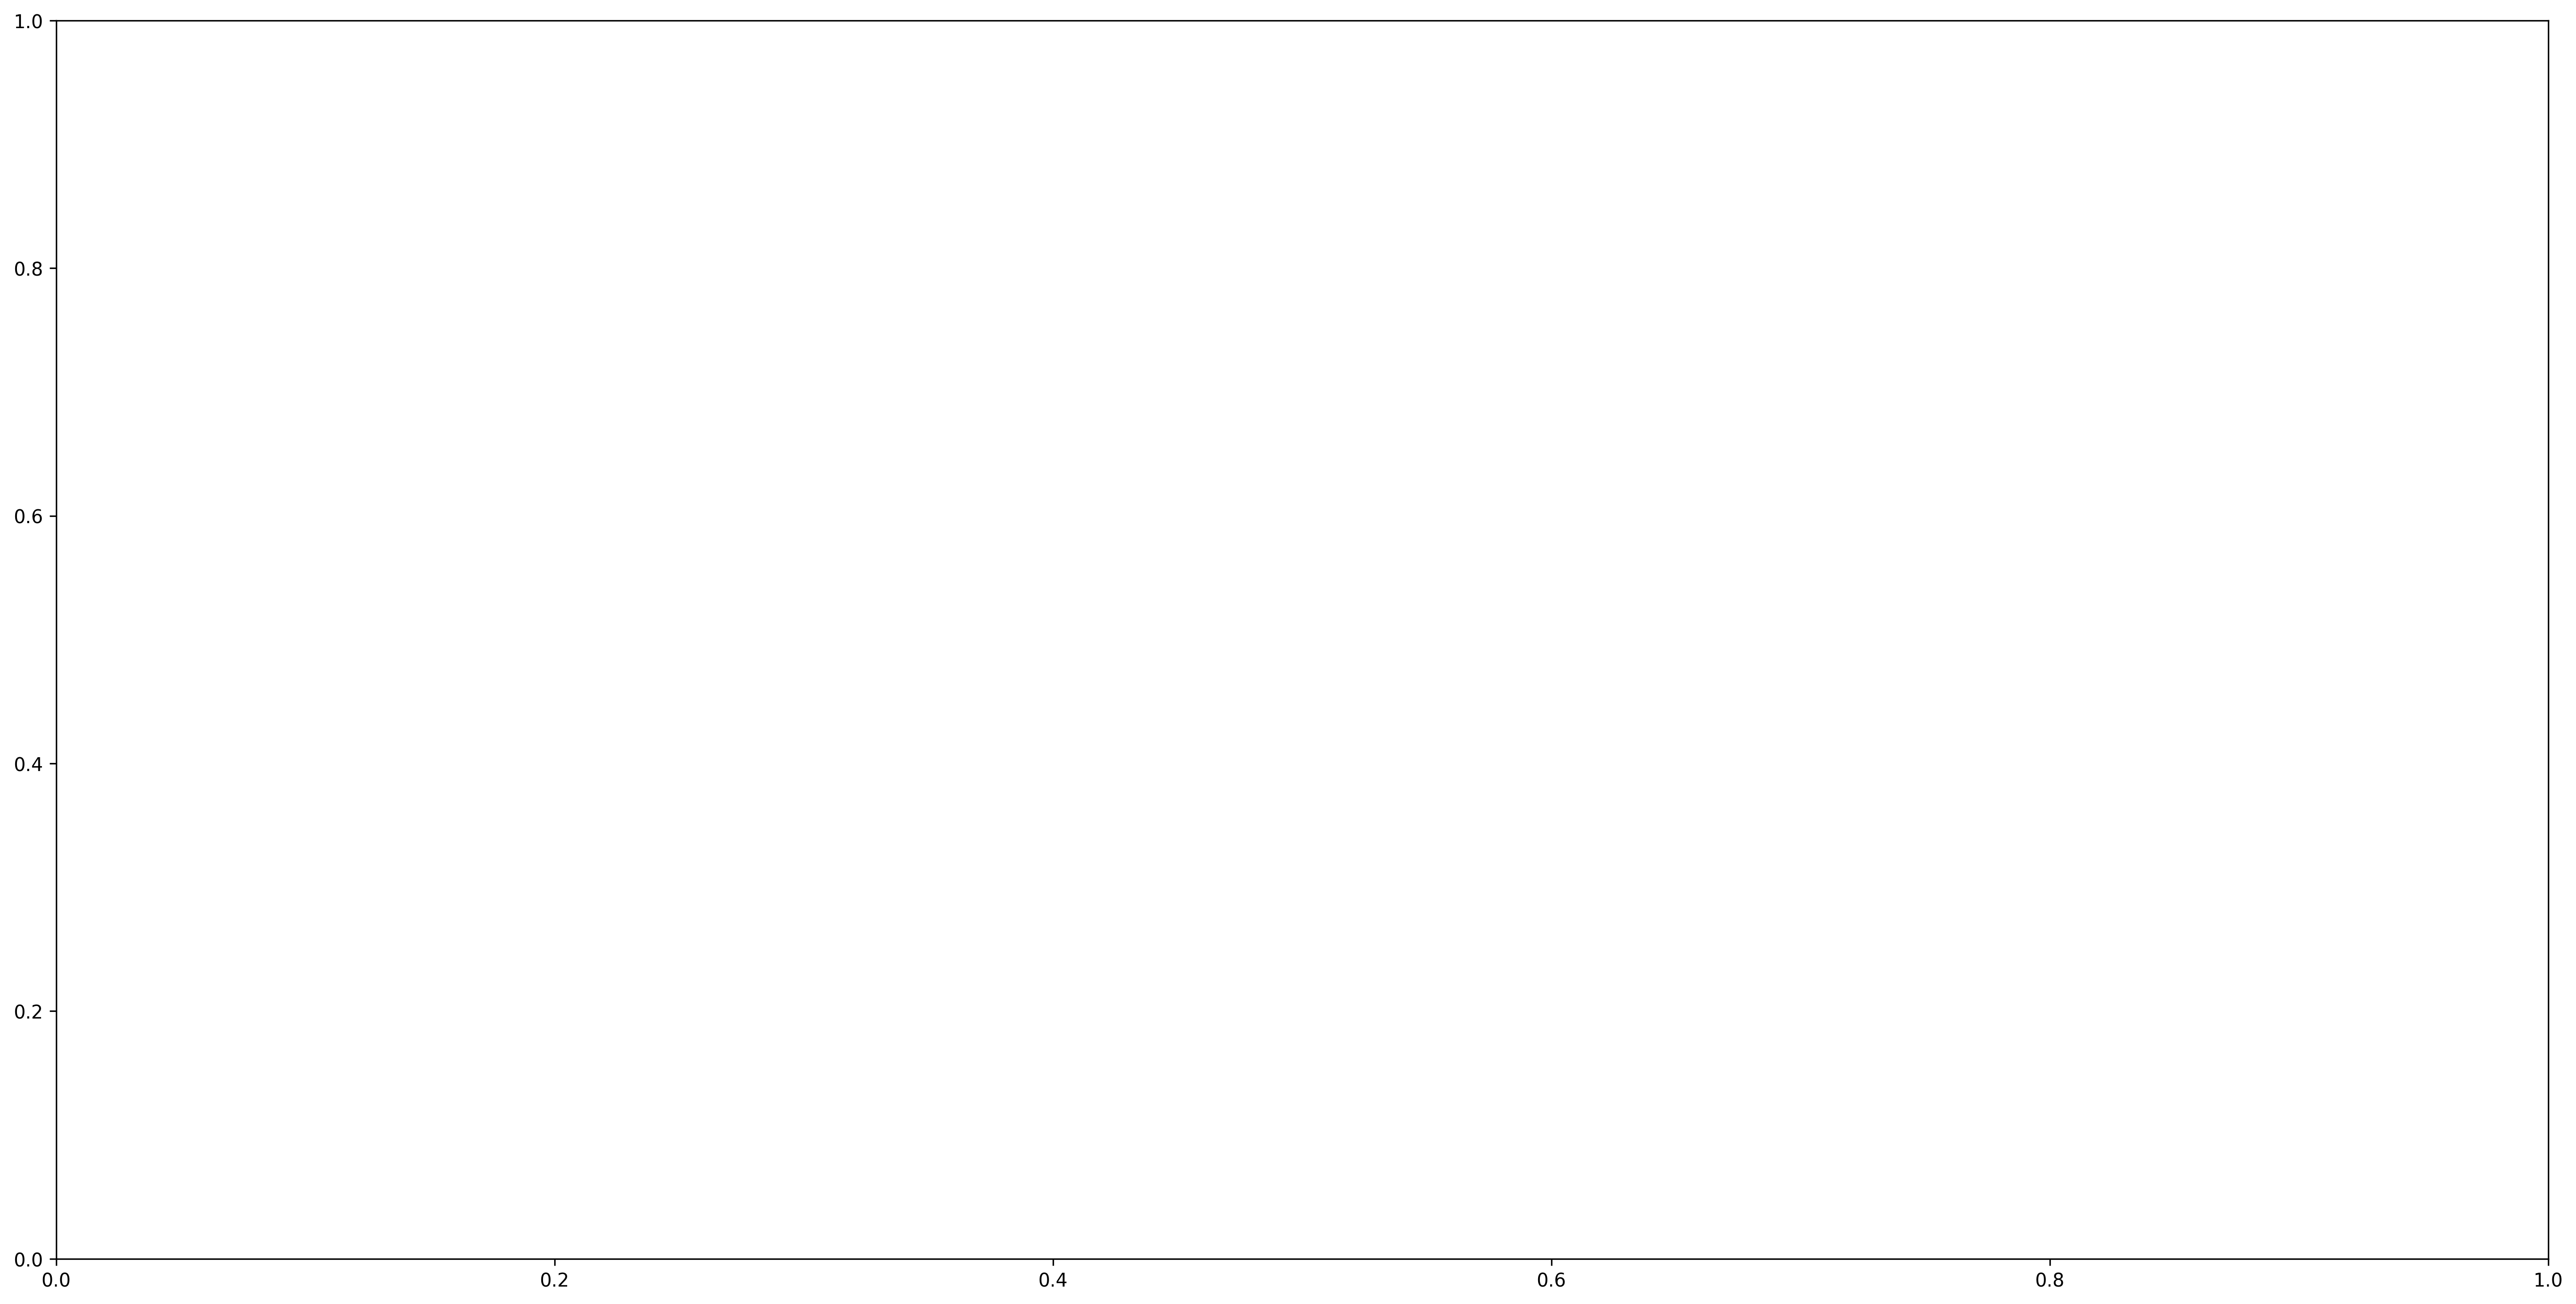

In [ ]:
# Create a figure with 300 DPI resolution
fig, ax = plt.subplots(figsize=(24, 12), dpi=300)

Explanation:

> In this section, we imported `Matplotlib` to create and display the graphical representation of the decision tree. We also imported `plot_tree()` from `scikit-learn`, which allows us to visualize the structure of the trained model and the decisions it makes when classifying the data.



**Plot the Decision Tree**

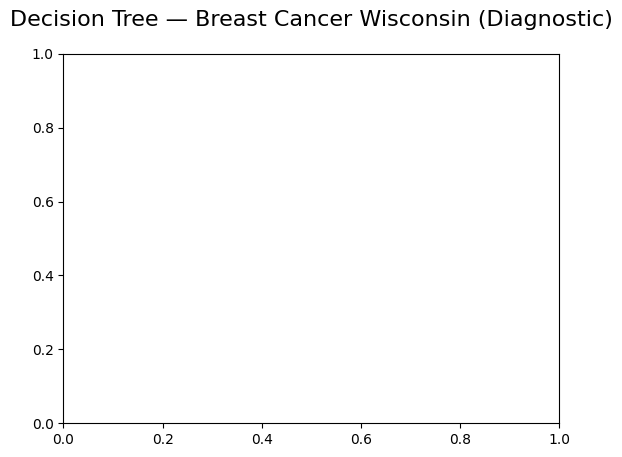

Figure saved as Decision_Tree.png at 300 DPI.


In [ ]:
# Plot the trained decision tree
_ = plot_tree(
    clf,
    feature_names=dataset.feature_names,
    class_names=dataset.target_names,
    filled=True,
    rounded=True,
    fontsize=7,
    ax=ax
)
plt.title("Decision Tree — Breast Cancer Wisconsin (Diagnostic)", fontsize=16, pad=20)
plt.savefig("Decision_Tree.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved as Decision_Tree.png at 300 DPI.")

Explanation:

> Finally, we used plot_tree() to see how the trained model makes its decisions. Each node shows a condition based on one of the tumor measurements. Following the branches leads to a predicted diagnosis. We added the feature and class names so the figure is easier to understand, and saved the image as a PNG at 300 DPI, as requested.

**Save desicion tree**

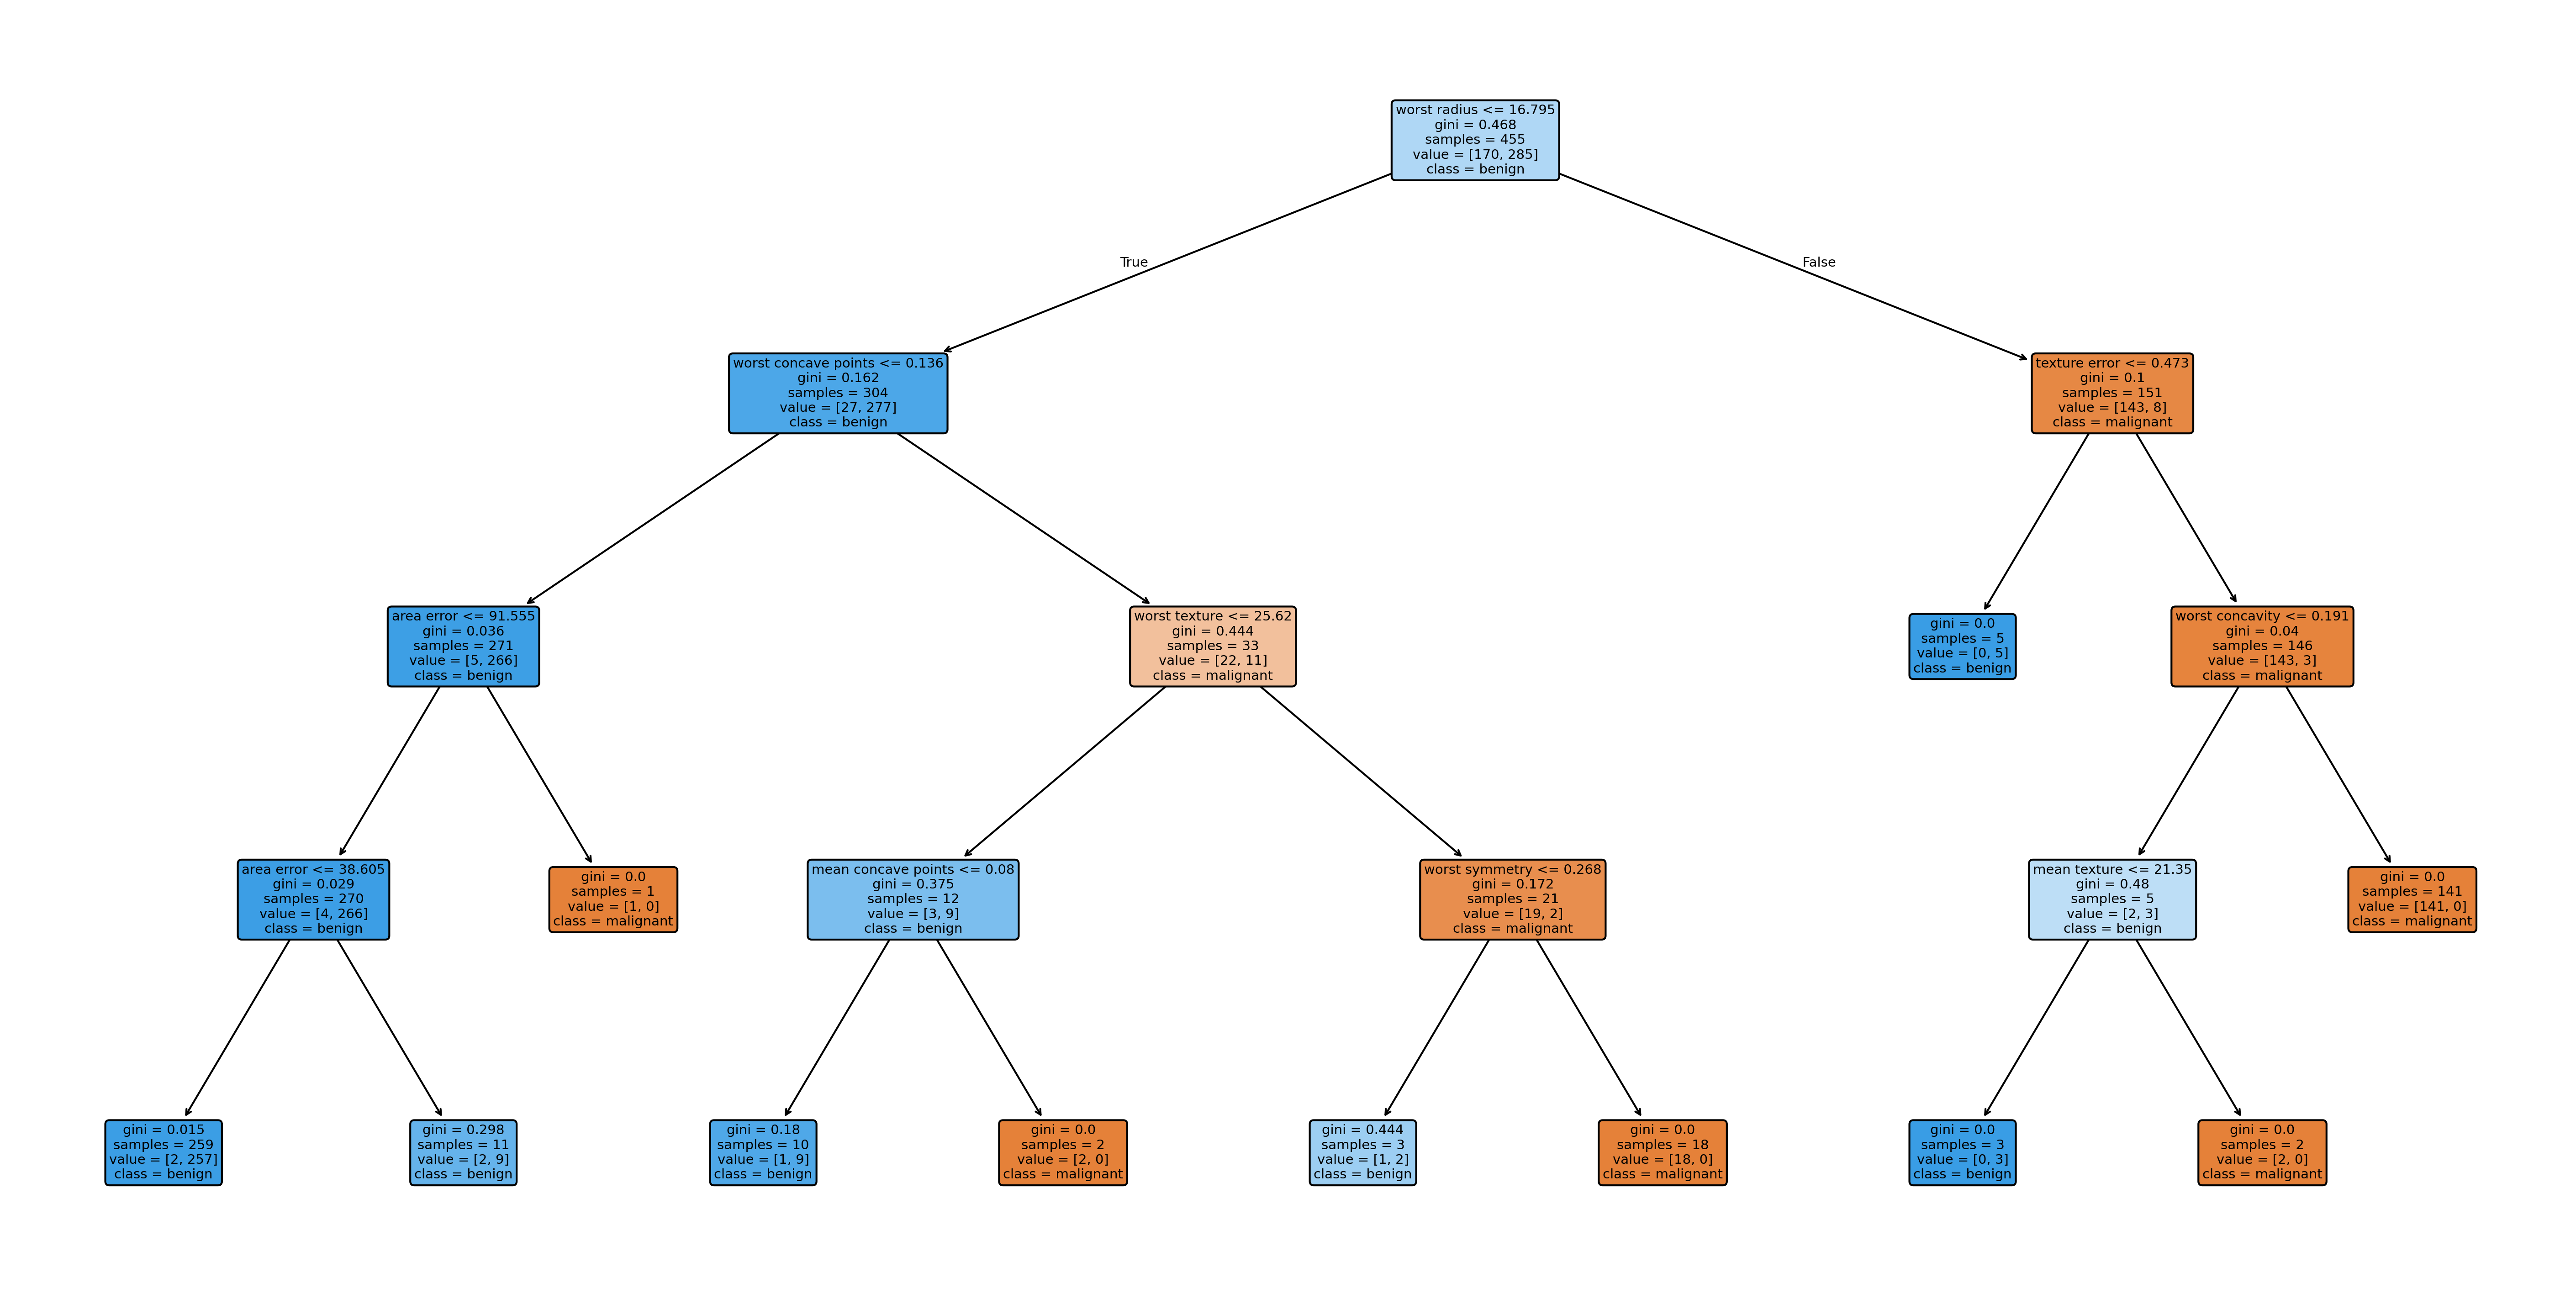

In [ ]:
# Save the decision tree as a PNG image
fig.savefig("Decision_Tree.png", dpi=300, bbox_inches="tight")

# Display the decision tree
display(fig)

**Comments on the results**



> With this split and these parameters, the decision tree correctly classifies 107 out of 114 test samples, giving an accuracy of 93.86%. It correctly identifies 39 of the 42 malignant cases and 68 of the 72 benign cases. The first split uses worst radius, and the following nodes use other measurements to separate the classes. These results are useful for this assignment, but errors still occur, so the model should not be treated as a clinical diagnostic tool.

